
# 04 — Model Explainability

## Objective

This notebook focuses on interpreting the selected Credit Risk model using SHAP (SHapley Additive exPlanations).

The objective is to understand how the model uses customer financial and repayment information to estimate the probability of credit default.

### Main objectives

- Identify the most influential features globally.
- Understand how feature values influence model predictions.
- Analyze individual default risk predictions.
- Communicate model behavior and limitations.

The selected Gradient Boosting pipeline was previously trained and saved during the experimental modeling stage. No additional model training will be performed in this notebook.


## . Conclusions and Limitations

### Global Explainability

SHAP analysis identified payment behavior as the most influential factor in the model's predictions. In particular, `PAY_1`, `TOTAL_DELAY_MONTHS`, `MRD`, and `PAY1_BILL1_INTERACTION` showed substantial predictive importance.

The results suggest that recent payment status and accumulated delinquency history play an important role in distinguishing default risk profiles. Engineered features also contributed relevant information beyond the original variables.

### Individual Explainability

The individual case study demonstrated how SHAP can decompose a prediction into positive and negative contributions.

For the selected customer, the model estimated a Probability of Default of 50.09%, and the observed outcome was default. The interaction between payment status and billing amount, together with accumulated delays, were the main positive contributors.

### Limitations

- SHAP values describe model behavior, not causal relationships.
- Correlated features and engineered interactions can distribute predictive contributions across multiple variables.
- The dataset represents historical credit card clients in Taiwan and may not reflect current Chilean credit risk conditions.
- The test set was previously used for model comparison and should not be considered an independent final validation set.
- The model is intended for portfolio analysis and explainability demonstrations, not real-world credit approval decisions.

### Final Remarks

This project demonstrates an end-to-end credit risk modeling workflow, combining feature engineering, gradient boosting, model evaluation, and explainability techniques.

The resulting pipeline provides reproducible Probability of Default estimates and interpretable insights into the factors influencing individual and global predictions.

In [10]:
from pathlib import Path
import sys
import joblib
import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. Configuración de rutas
# --------------------------------------------------

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# --------------------------------------------------
# 2. Importar FeatureEngineer
# --------------------------------------------------

from src.feature_engineering import FeatureEngineer

# --------------------------------------------------
# 3. Cargar pipeline entrenado
# --------------------------------------------------

MODEL_PATH = PROJECT_ROOT / "models" / "credit_risk_pipeline_v1.joblib"

final_pipeline = joblib.load(MODEL_PATH)

# --------------------------------------------------
# 4. Cargar conjuntos de datos
# --------------------------------------------------

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "train_test_split.joblib"

datasets = joblib.load(DATA_PATH)

X_train_base = datasets["X_train_base"]
X_test_base = datasets["X_test_base"]
y_train = datasets["y_train"]
y_test = datasets["y_test"]

print("Inicialización completada correctamente.")


Inicialización completada correctamente.


In [11]:
print("Pipeline:", type(final_pipeline))
print("X_train_base:", X_train_base.shape)
print("X_test_base:", X_test_base.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Comprobar predicciones
y_proba = final_pipeline.predict_proba(X_test_base)[:, 1]

print("\nPredicciones generadas:", len(y_proba))
print("Probabilidad mínima:", y_proba.min())
print("Probabilidad máxima:", y_proba.max())
print("¿Todas las probabilidades son válidas?:", np.isfinite(y_proba).all())

Pipeline: <class 'sklearn.pipeline.Pipeline'>
X_train_base: (24000, 22)
X_test_base: (6000, 22)
y_train: (24000,)
y_test: (6000,)

Predicciones generadas: 6000
Probabilidad mínima: 0.0356338296810984
Probabilidad máxima: 0.8673050975977703
¿Todas las probabilidades son válidas?: True


In [13]:
import shap
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [14]:
# Extraer componentes del pipeline
feature_engineer = final_pipeline.named_steps["feature_engineering"]
preprocessor = final_pipeline.named_steps["preprocessor"]
model = final_pipeline.named_steps["model"]

# Aplicar Feature Engineering
X_test_fe = feature_engineer.transform(X_test_base)

# Aplicar preprocessing
X_test_transformed = preprocessor.transform(X_test_fe)

print("Datos originales:", X_test_base.shape)
print("Después de Feature Engineering:", X_test_fe.shape)
print("Después de preprocessing:", X_test_transformed.shape)
print("Modelo:", type(model).__name__)

Datos originales: (6000, 22)
Después de Feature Engineering: (6000, 39)
Después de preprocessing: (6000, 39)
Modelo: GradientBoostingClassifier


In [15]:
feature_names = preprocessor.get_feature_names_out()

print("Número de variables:", len(feature_names))
print("\nPrimeras 15 variables:")

for feature in feature_names[:15]:
    print("-", feature)

Número de variables: 39

Primeras 15 variables:
- numeric__LIMIT_BAL
- numeric__EDUCATION
- numeric__MARRIAGE
- numeric__AGE
- numeric__PAY_1
- numeric__PAY_2
- numeric__PAY_3
- numeric__PAY_4
- numeric__PAY_5
- numeric__PAY_6
- numeric__BILL_AMT1
- numeric__BILL_AMT2
- numeric__BILL_AMT3
- numeric__BILL_AMT4
- numeric__BILL_AMT5


In [16]:
# Crear explicador SHAP
explainer = shap.TreeExplainer(model)

# Calcular valores SHAP sobre el conjunto de prueba
shap_values = explainer.shap_values(X_test_transformed)

print("Tipo de resultado:", type(shap_values))
print("Dimensiones SHAP:", np.array(shap_values).shape)

Tipo de resultado: <class 'numpy.ndarray'>
Dimensiones SHAP: (6000, 39)


In [17]:
# Importancia global mediante mean absolute SHAP
shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

# Mostrar top 20
display(shap_importance.head(20))

,feature,mean_abs_shap
37,numeric__PAY1_BILL1_INTERACTION,0.264975
4,numeric__PAY_1,0.172610
22,numeric__TOTAL_DELAY_MONTHS,0.137179
23,numeric__MRD,0.112907
10,numeric__BILL_AMT1,0.106223
0,numeric__LIMIT_BAL,0.102448
25,numeric__UTIL_RATE_1,0.097522
26,numeric__UTIL_RATE_AVG,0.087249
17,numeric__PAY_AMT2,0.083016
16,numeric__PAY_AMT1,0.070533


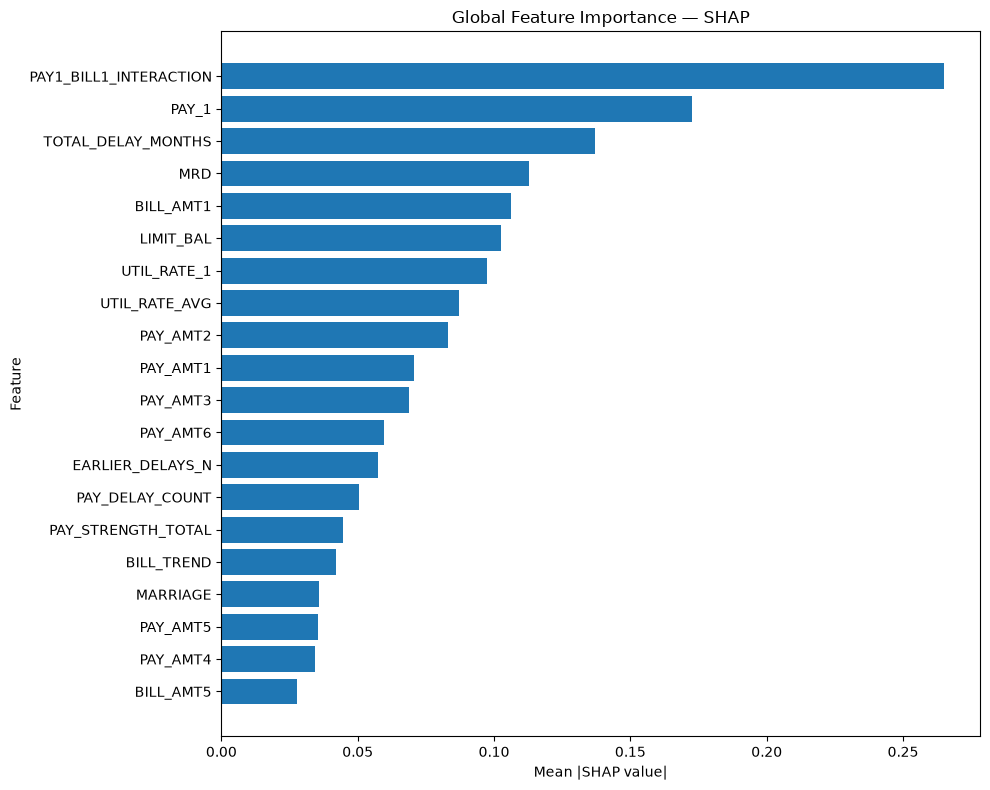

In [18]:
plt.figure(figsize=(10, 8))

top_features = shap_importance.head(20).sort_values("mean_abs_shap")

plt.barh(
    top_features["feature"].str.replace("numeric__", "", regex=False),
    top_features["mean_abs_shap"]
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Feature")
plt.title("Global Feature Importance — SHAP")
plt.tight_layout()
plt.show()

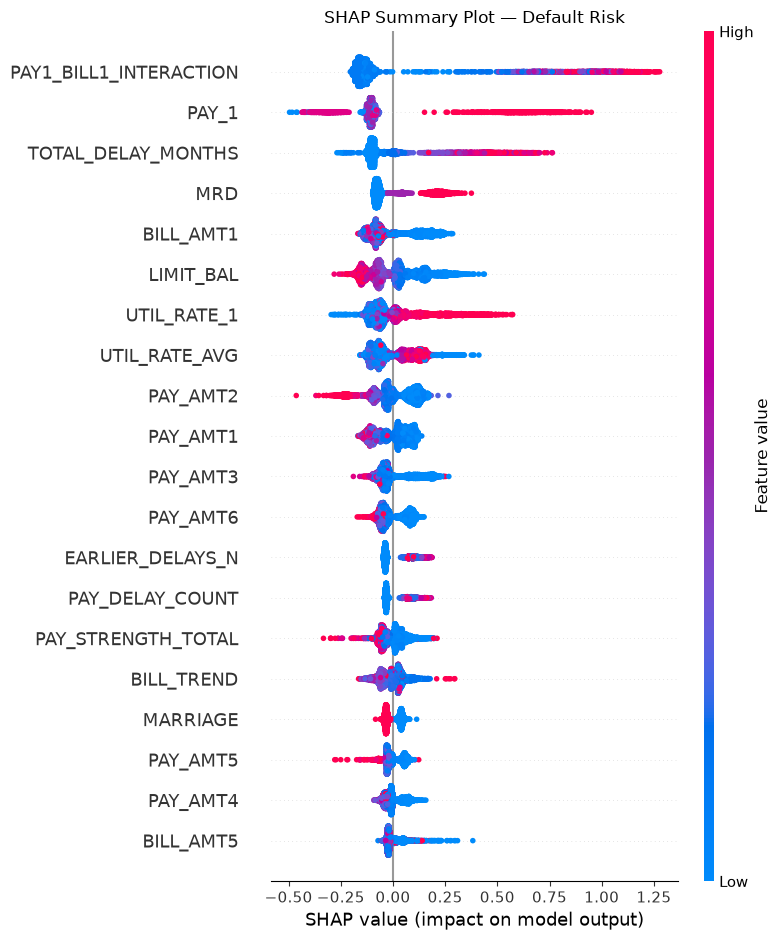

In [19]:
# Preparar nombres más legibles
clean_feature_names = [
    name.replace("numeric__", "") for name in feature_names
]

X_shap = pd.DataFrame(
    X_test_transformed,
    columns=clean_feature_names,
    index=X_test_base.index
)

# Beeswarm: 20 variables principales
shap.summary_plot(
    shap_values,
    X_shap,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot — Default Risk")
plt.tight_layout()
plt.show()

In [20]:
# Construir resumen numérico por variable
shap_numeric_summary = pd.DataFrame({
    "feature": clean_feature_names,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0),
    "mean_shap": shap_values.mean(axis=0),
    "mean_positive_impact": np.where(
        shap_values > 0, shap_values, 0
    ).mean(axis=0),
    "mean_negative_impact": np.where(
        shap_values < 0, shap_values, 0
    ).mean(axis=0),
    "pct_increases_PD": (shap_values > 0).mean(axis=0) * 100,
    "pct_decreases_PD": (shap_values < 0).mean(axis=0) * 100
})

shap_numeric_summary = (
    shap_numeric_summary
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

display(
    shap_numeric_summary.head(20).round(4)
)

,feature,mean_abs_shap,mean_shap,mean_positive_impact,mean_negative_impact,pct_increases_PD,pct_decreases_PD
0,PAY1_BILL1_INTERACTION,0.2650,0.0280,0.1465,-0.1185,17.0167,82.9833
1,PAY_1,0.1726,-0.0412,0.0657,-0.1069,10.6000,89.4000
2,TOTAL_DELAY_MONTHS,0.1372,-0.0058,0.0657,-0.0715,24.1000,75.9000
3,MRD,0.1129,0.0112,0.0620,-0.0509,32.4500,67.5500
4,BILL_AMT1,0.1062,-0.0064,0.0499,-0.0563,34.8333,65.1667
5,LIMIT_BAL,0.1024,0.0039,0.0532,-0.0493,50.4500,49.5500
6,UTIL_RATE_1,0.0975,0.0022,0.0499,-0.0476,37.3000,62.7000
7,UTIL_RATE_AVG,0.0872,-0.0006,0.0433,-0.0439,42.4500,57.5500
8,PAY_AMT2,0.0830,0.0060,0.0445,-0.0385,46.2333,53.7667
9,PAY_AMT1,0.0705,0.0012,0.0359,-0.0347,58.0000,42.0000


In [21]:
# Variables seleccionadas
selected_features = [
    "PAY_1",
    "TOTAL_DELAY_MONTHS",
    "PAY1_BILL1_INTERACTION"
]

# Construir tablas por rangos
for feature in selected_features:

    analysis = pd.DataFrame({
        "feature_value": X_test_fe[feature].values,
        "shap_value": shap_values[:, feature_names.tolist().index(
            f"numeric__{feature}"
        )]
    })

    # Agrupar por valor observado
    summary = (
        analysis.groupby("feature_value")
        .agg(
            clients=("shap_value", "size"),
            mean_shap=("shap_value", "mean"),
            mean_abs_shap=("shap_value", lambda x: np.abs(x).mean())
        )
        .reset_index()
        .sort_values("feature_value")
    )

    print(f"\n--- SHAP analysis: {feature} ---")
    display(summary.round(4))


--- SHAP analysis: PAY_1 ---


,feature_value,clients,mean_shap,mean_abs_shap
0,-2,561,-0.1210,0.1210
1,-1,1159,-0.0935,0.0935
2,0,2956,-0.1087,0.1087
3,1,688,-0.2093,0.2093
4,2,529,0.6399,0.6399
5,3,77,0.5821,0.5821
6,4,18,0.4005,0.4005
7,5,8,0.3144,0.3144
8,6,1,0.3057,0.3057
9,8,3,0.2730,0.2730



--- SHAP analysis: TOTAL_DELAY_MONTHS ---


,feature_value,clients,mean_shap,mean_abs_shap
0,0,4035,-0.1013,0.1013
1,1,307,-0.0582,0.0582
2,2,545,0.0090,0.0147
3,3,151,0.0091,0.0209
4,4,196,0.2370,0.2370
5,5,77,0.3248,0.3248
6,6,132,0.4065,0.4065
7,7,78,0.4347,0.4347
8,8,92,0.4754,0.4754
9,9,41,0.5020,0.5020



--- SHAP analysis: PAY1_BILL1_INTERACTION ---


,feature_value,clients,mean_shap,mean_abs_shap
0,-956060,1,0.1695,0.1695
1,-781024,1,0.2618,0.2618
2,-646816,1,0.1062,0.1062
3,-503188,1,0.2713,0.2713
4,-481854,1,0.1271,0.1271
...,...,...,...,...
2345,1013030,1,0.8870,0.8870
2346,1082175,1,0.9432,0.9432
2347,1227720,1,1.1991,1.1991
2348,1442925,1,1.1716,1.1716


In [22]:
feature = "PAY1_BILL1_INTERACTION"

analysis = pd.DataFrame({
    "feature_value": X_test_fe[feature].values,
    "shap_value": shap_values[:, feature_names.tolist().index(
        f"numeric__{feature}"
    )]
})

analysis["value_decile"] = pd.qcut(
    analysis["feature_value"],
    q=10,
    duplicates="drop"
)

interaction_summary = (
    analysis.groupby("value_decile", observed=True)
    .agg(
        clients=("shap_value", "size"),
        mean_feature_value=("feature_value", "mean"),
        mean_shap=("shap_value", "mean"),
        mean_abs_shap=("shap_value", lambda x: np.abs(x).mean())
    )
    .reset_index()
)

display(interaction_summary.round(4))

,value_decile,clients,mean_feature_value,mean_shap,mean_abs_shap
0,"(-956060.001, -5692.4]",600,-35784.7200,-0.1140,0.1265
1,"(-5692.4, -784.6]",600,-2664.7983,-0.1287,0.1287
2,"(-784.6, 0.0]",3739,-42.0182,-0.1481,0.1481
3,"(0.0, 40926.3]",461,15652.3818,0.6317,0.6653
4,"(40926.3, 1975320.0]",600,180941.5300,0.9605,0.9605


In [23]:
# Buscar cliente cuya PD esté más cerca del 50%
target_pd = 0.50

individual_idx = np.argmin(np.abs(y_proba - target_pd))

individual_pd = y_proba[individual_idx]

print("Índice del cliente:", individual_idx)
print(f"Probability of Default: {individual_pd:.2%}")
print("Default real:", y_test.iloc[individual_idx])

Índice del cliente: 39
Probability of Default: 50.09%
Default real: 1


In [24]:
# Extraer valores SHAP del cliente seleccionado
individual_shap = shap_values[individual_idx]

individual_features = pd.DataFrame({
    "feature": clean_feature_names,
    "feature_value": X_shap.iloc[individual_idx].values,
    "shap_value": individual_shap
})

individual_features["impact"] = np.where(
    individual_features["shap_value"] > 0,
    "Increases risk",
    "Reduces risk"
)

# Ordenar por magnitud de contribución
individual_features["abs_shap"] = individual_features["shap_value"].abs()

individual_features = individual_features.sort_values(
    "abs_shap", ascending=False
).reset_index(drop=True)

display(individual_features.head(15).round(4))

# Comprobar la descomposición aditiva
base_value = float(np.asarray(explainer.expected_value).reshape(-1)[0])
shap_output = base_value + individual_shap.sum()

print(f"\nBase value: {base_value:.4f}")
print(f"SHAP output: {shap_output:.4f}")
print(f"Model output (decision function): "
      f"{model.decision_function(X_test_transformed)[individual_idx]:.4f}")

,feature,feature_value,shap_value,impact,abs_shap
0,PAY1_BILL1_INTERACTION,24305.0000,0.6292,Increases risk,0.6292
1,PAY_1,1.0000,-0.2976,Reduces risk,0.2976
2,TOTAL_DELAY_MONTHS,5.0000,0.2843,Increases risk,0.2843
3,MRD,2.0000,0.1797,Increases risk,0.1797
4,LIMIT_BAL,30000.0000,0.1520,Increases risk,0.1520
5,BILL_TREND,-2163.3333,0.1045,Increases risk,0.1045
6,UTIL_RATE_AVG,0.8391,0.1009,Increases risk,0.1009
7,PAY_AMT2,1410.0000,0.0904,Increases risk,0.0904
8,PAY_DELAY_COUNT,3.0000,0.0892,Increases risk,0.0892
9,EARLIER_DELAYS_N,3.0000,0.0873,Increases risk,0.0873



Base value: -1.5367
SHAP output: 0.0035
Model output (decision function): 0.0035


In [25]:
#guardar graficos

In [26]:
from pathlib import Path

IMAGES_DIR = PROJECT_ROOT / "images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

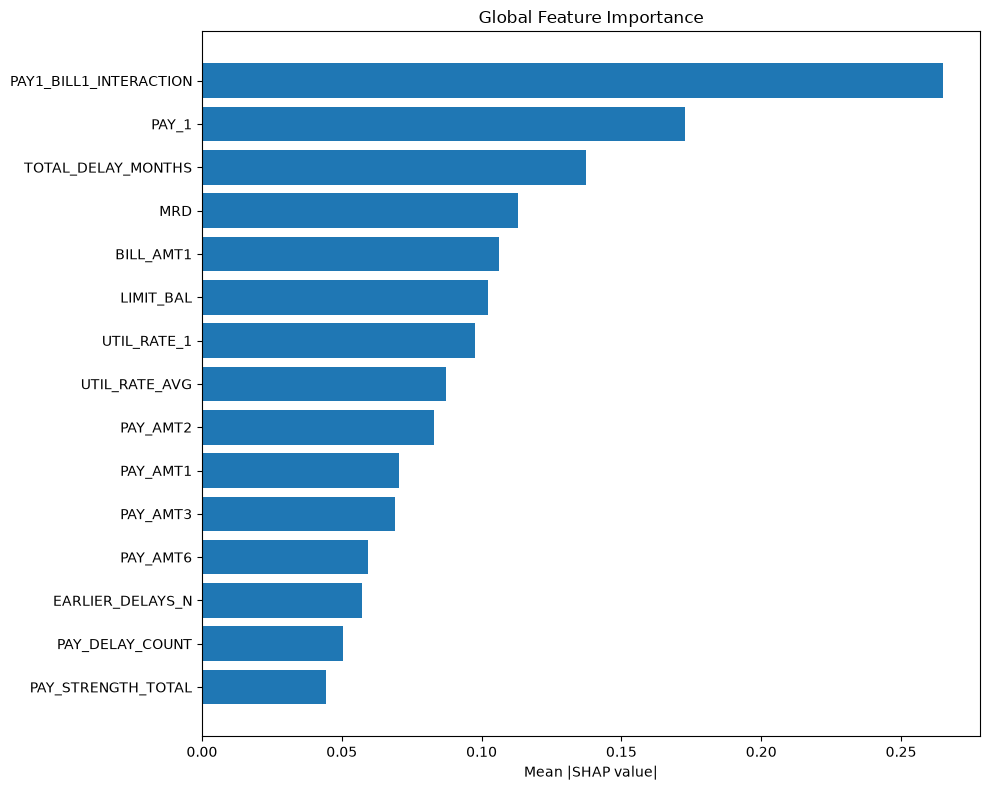

In [27]:
plt.figure(figsize=(10, 8))

top_features = shap_importance.head(15).sort_values("mean_abs_shap")

plt.barh(
    top_features["feature"].str.replace("numeric__", "", regex=False),
    top_features["mean_abs_shap"]
)

plt.xlabel("Mean |SHAP value|")
plt.title("Global Feature Importance")
plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

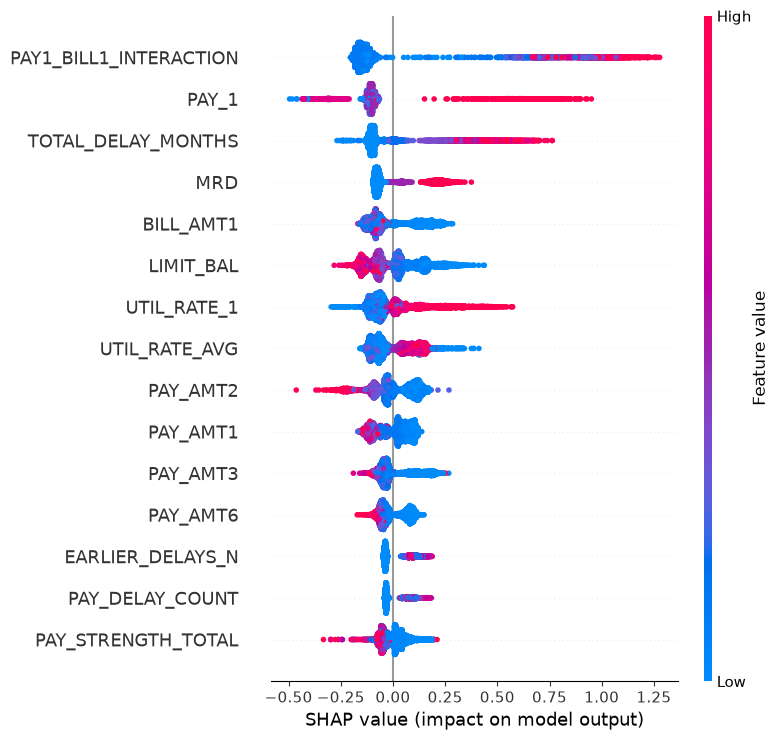

In [29]:
plt.figure(figsize=(11, 8))

shap.summary_plot(
    shap_values,
    X_shap,
    max_display=15,
    show=False
)

plt.savefig(
    IMAGES_DIR / "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

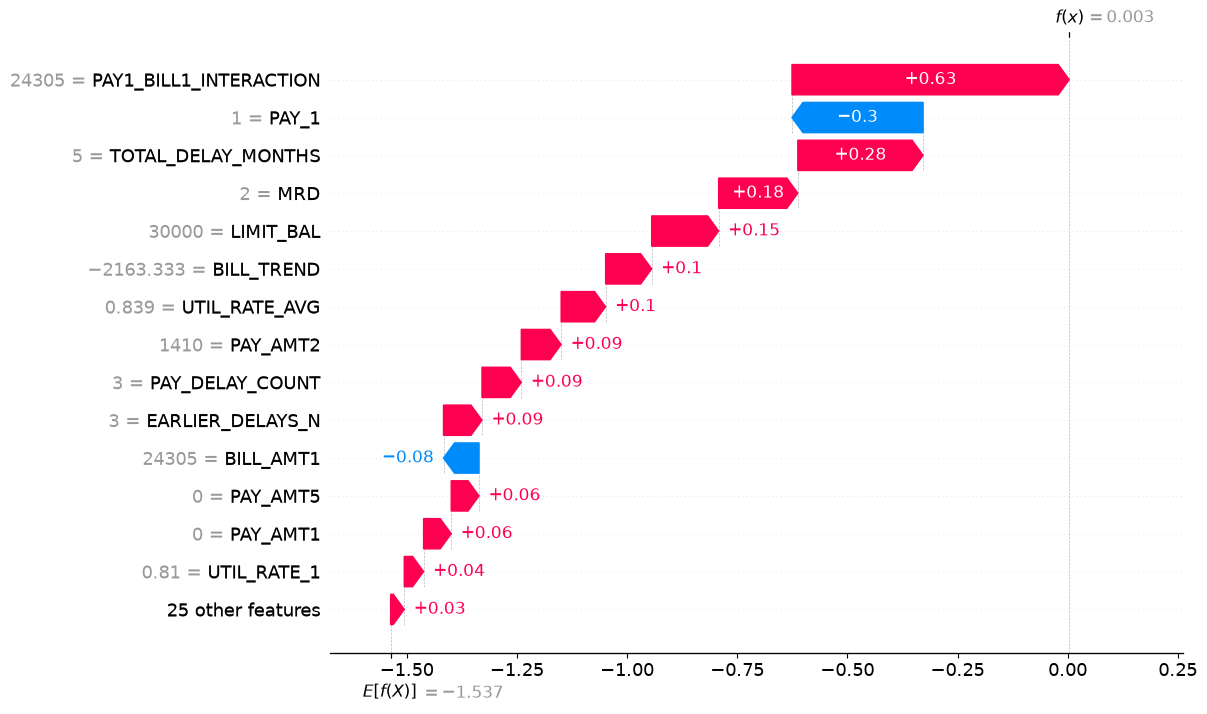

In [31]:
individual_explanation = shap.Explanation(
    values=individual_shap,
    base_values=float(np.asarray(explainer.expected_value).flatten()[0]),
    data=X_shap.iloc[individual_idx].values,
    feature_names=clean_feature_names
)

shap.plots.waterfall(
    individual_explanation,
    max_display=15,
    show=False
)

plt.gcf().set_size_inches(11, 8)
plt.savefig(
    IMAGES_DIR / "shap_individual_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()